### ⚙️ Environment Setup  
This setup uses **GROMACS 2023 + PLUMED installed in home directory on ACCRE**.  
Install Gromacs 2023 patched with plummed to your home directory and load all modules to run
Update module loads or source your own `GMXRC` if running on a different HPC to ensure the correct environment is activated.

This part changes the most when running on HPC systems other than ACCRE, since the workflow was tailored specifically for ACCRE’s environment.

In [14]:
import os
import subprocess

def load_gmx_plumed():
    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2
    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC
    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH
    env
    """
    # run in bash, capture environment
    result = subprocess.run(cmd, shell=True, executable="/bin/bash", capture_output=True, text=True)
    for line in result.stdout.splitlines():
        key, _, value = line.partition("=")
        os.environ[key] = value


**Load the function defined above**

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import subprocess
import os
from contextlib import contextmanager
import re
import pandas
import pathlib

Import these modules for convenience 

In [16]:
load_gmx_plumed()

**Set your working directory here. Replace this path with your own**

In [17]:
%cd /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Exchange/6ONI

/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Exchange/6ONI


### ⚡ Energy Extraction  
**Pull out the potential energy from every replica’s `ener.edr` file** and store it as `potential.xvg` inside each temperature folder for fast, organized analysis.


In [30]:
%%bash
for T in 100 102 104 106 108 110 112 114 116 118; do
  gmx_mpi energy -f $T/ener.edr -o $T/potential.xvg <<EOF
Potential
EOF
done

bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us


Statistics over 100000001 steps [ 0.0000 through 200000.0000 ps ], 1 data sets
All statistics are over 1000001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   1810.02       0.28    60.4334   0.155453  (kJ/mol)


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Exchange/6ONI
Command line:
  gmx_mpi energy -f 102/ener.edr -o 102/potential.xvg

Opened 102/ener.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Improper-Dih. 
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Coulomb-(SR)  
  9  Potential       10  Kinetic-En.     11  Total-Energy    12  Temperature   
 13  Pressure        14  Vir-XX          15  Vir-XY          16  Vir-XZ        
 17  Vir-YX          18  Vir-YY    


Statistics over 100000001 steps [ 0.0000 through 200000.0000 ps ], 1 data sets
All statistics are over 1000001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   1899.06       0.39    62.9943   -1.14365  (kJ/mol)


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Exchange/6ONI
Command line:
  gmx_mpi energy -f 104/ener.edr -o 104/potential.xvg

Opened 104/ener.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Improper-Dih. 
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Coulomb-(SR)  
  9  Potential       10  Kinetic-En.     11  Total-Energy    12  Temperature   
 13  Pressure        14  Vir-XX          15  Vir-XY          16  Vir-XZ        
 17  Vir-YX          18  Vir-YY    

...


Statistics over 100000001 steps [ 0.0000 through 200000.0000 ps ], 1 data sets
All statistics are over 1000001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   3254.63       0.96    60.3199    5.81621  (kJ/mol)


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Exchange/6ONI
Command line:
  gmx_mpi energy -f 116/ener.edr -o 116/potential.xvg

Opened 116/ener.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Improper-Dih. 
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Coulomb-(SR)  
  9  Potential       10  Kinetic-En.     11  Total-Energy    12  Temperature   
 13  Pressure        14  Vir-XX          15  Vir-XY          16  Vir-XZ        
 17  Vir-YX          18  Vir-YY    


Statistics over 100000001 steps [ 0.0000 through 200000.0000 ps ], 1 data sets
All statistics are over 1000001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   3311.52       0.61    58.7752    3.56133  (kJ/mol)


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Exchange/6ONI
Command line:
  gmx_mpi energy -f 118/ener.edr -o 118/potential.xvg

Opened 118/ener.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Improper-Dih. 
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Coulomb-(SR)  
  9  Potential       10  Kinetic-En.     11  Total-Energy    12  Temperature   
 13  Pressure        14  Vir-XX          15  Vir-XY          16  Vir-XZ        
 17  Vir-YX          18  Vir-YY    


Statistics over 100000001 steps [ 0.0000 through 200000.0000 ps ], 1 data sets
All statistics are over 1000001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   3367.02        0.5     58.715    2.73363  (kJ/mol)


### 📊 Energy Distribution Plot  
Creates overlapping histograms of **potential energy** from all temperature replicas to visualize sampling quality.

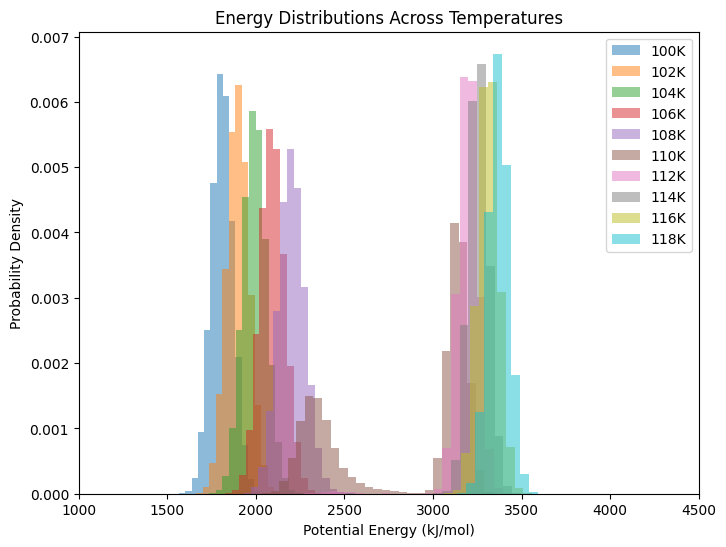

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import glob

temps = [100,102,104,106,108,110,112,114,116,118]
plt.figure(figsize=(8,6))

for T in temps:
    data = np.loadtxt(f"{T}/potential.xvg", comments=["@", "#"])
    E = data[:,1]
    plt.hist(E, bins=100, density=True, alpha=0.5, label=f"{T}K")

plt.xlabel("Potential Energy (kJ/mol)")
plt.ylabel("Probability Density")
plt.legend()
plt.title("Energy Distributions Across Temperatures")
plt.xlim(1000, 4500)

plt.show()


### 🔍 Concise Explanation of the Energy Distribution Plot (6ONI)

The energy distributions for 6ONI reveal **two dominant regimes** rather than a clearly separated three-state pattern:

### <p style="text-align:center; font-size:20px;"><b>N ⟷ (I?) ⟷ U</b></p>

- **N 🔶 100–106 K → Native Basin (~2000 kJ/mol)**  
  At lower temperatures, the histograms cluster tightly around ~2000 kJ/mol.  
  This indicates that 6ONI predominantly samples the **native basin**, with little evidence of significant structural disruption.

- **(I?) 🔷 108–110 K → Possible Broadening, Not a Clear Intermediate (~2300–2600 kJ/mol)**  
  As the temperature increases, the distributions **broaden and shift slightly**, but unlike 6ONJ or 3PRG, there is **no distinct, well-separated peak** around ~2500 kJ/mol.  
 **This suggests that the starting crystallographic conformation of *6ONI* does not sample the intermediate state as efficiently as the agonist-like starting conformations used in *3PRG* and *6ONJ*.**

- **U 🔺 >3000 kJ/mol → Unfolded Basin**  
  The high-energy peak above ~3000 kJ/mol corresponds to the **unfolded ensemble**.  
  The gap between native and unfolded energies remains large, indicating that **full unfolding requires substantial energy input**, consistent with a cooperative transition.
---

### 📌 Summary

Unlike 6ONJ or 3PRG—where SMOG models clearly reveal a **well-defined intermediate basin**—the 6ONI system shows **native and unfolded basins only**, with **no sharply resolved intermediate**.  
The slight broadening in the 108–110 K range may reflect **native loosening or marginal partial unfolding**, but the absence of a separated energy peak implies that **6ONI behaves more like a two-state folder** under this model. 

This distinction is important:  
**6ONI = mostly N ↔ U transition, weak or unresolved I**  
**6ONJ / 3PRG = strong, stable, well-separated intermediate**
_________

### 🔀 Replica Demultiplexing  
Run the **demux.pl** script (taken from the repository: https://github.com/srnas/demux/tree/master) to generate the replica–temperature mapping from your REMD logs:

In [32]:
!demux.pl 100/md.log

/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

### 🔄 Walker Exchange Visualization  
Plot the **replica–temperature movement** across the temperature ladder to verify proper SMOG REMD mixing and walker mobility

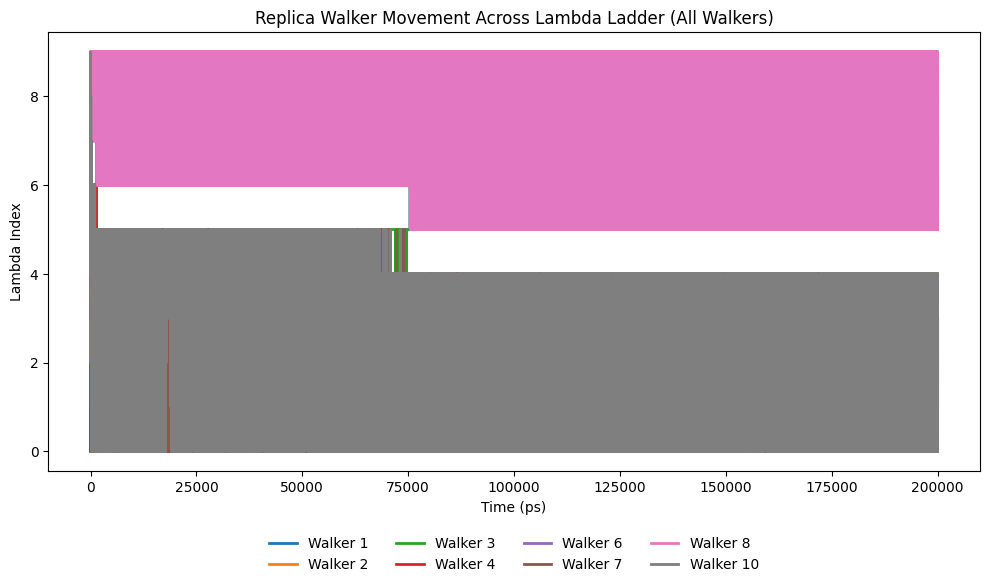

In [9]:
import numpy as np
import matplotlib.pyplot as plt

rep = np.loadtxt("replica_temp.xvg", comments=["#", "@"])
time = rep[:,0]

plt.figure(figsize=(10,6))

# choose representative walkers (change list if needed)
walkers_to_label = np.linspace(1, rep.shape[1]-1, 8, dtype=int)

for i in range(1, rep.shape[1]):
    plt.plot(time, rep[:,i], linewidth=0.8, alpha=0.4)

# overlay selected walkers thicker + labeled
for w in walkers_to_label:
    plt.plot(time, rep[:,w], linewidth=2, label=f"Walker {w}")

plt.xlabel("Time (ps)")
plt.ylabel("Lambda Index")
plt.title("Replica Walker Movement Across Lambda Ladder (All Walkers)")

# 📍 Legend below plot
plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=4,
    frameon=False
)

plt.tight_layout()
plt.show()


### 📌 Note  
When plotting all walkers together, **walkers 1–10 overlap heavily**, making the visualization unclear.  
To focus on specific walkers, adjust:

`walkers_to_plot = [4, 5]`

You can add any walker indices you want to visualize more clearly.


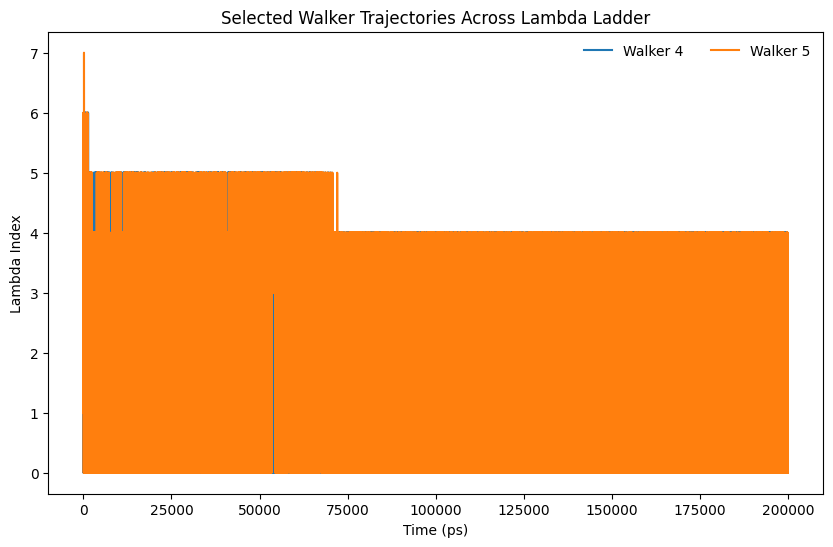

In [36]:
walkers_to_plot = [4,5]  # index in replica_temp (1 = λ001 walker)

plt.figure(figsize=(10,6))
for w in walkers_to_plot:
    plt.plot(time, rep[:, w], linewidth=1.5, label=f"Walker {w}")

plt.xlabel("Time (ps)")
plt.ylabel("Lambda Index")
plt.title("Selected Walker Trajectories Across Lambda Ladder")
plt.legend(ncol=3, frameon=False)
plt.show()


### **Result**

Walkers **4 and 5** remain confined within the lowest temperature range   (**100–110 K**, corresponding to replicas **0–5** respectively) and **do not diffuse** into the  higher-energy, unfolded region.
This indicates that these walkers are **effectively  trapped in the native ↔ intermediate regime**, without successful exchange into the unfolded basin.


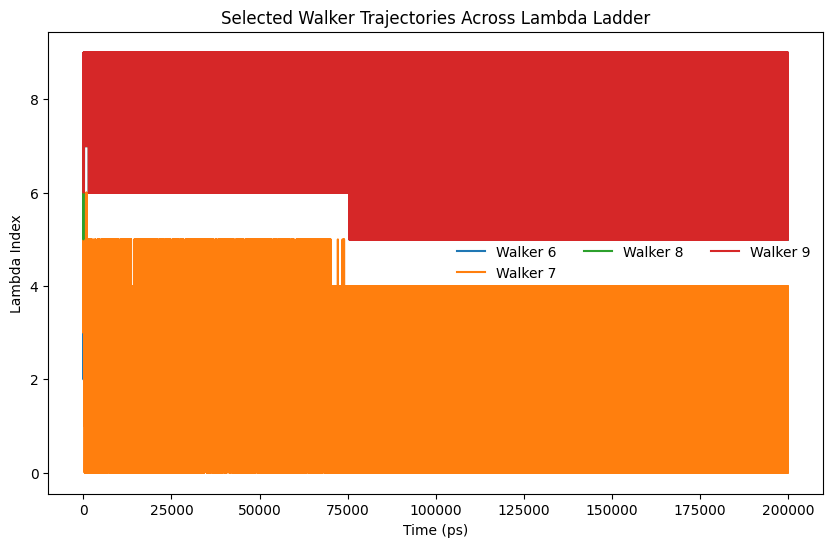

In [40]:
walkers_to_plot = [6,7,8,9]  # index in replica_temp (1 = λ001 walker)

plt.figure(figsize=(10,6))
for w in walkers_to_plot:
    plt.plot(time, rep[:, w], linewidth=1.5, label=f"Walker {w}")

plt.xlabel("Time (ps)")
plt.ylabel("Lambda Index")
plt.title("Selected Walker Trajectories Across Lambda Ladder")
plt.legend(ncol=3, frameon=False)
plt.show()


### **Result**

Walkers **6, 8 and 9** remain confined within the highest temperature range   (**110–118 K**, corresponding to replicas **0–5** respectively) and **do not diffuse** into the  higher-energy, unfolded region.
This indicates that these walkers are **effectively  trapped in the unfolded regime**, without successful exchange into the native ↔ intermediate regime.

Walker 7 diffuses into the folded region at the start of the simulation.  
This exchange occurs *before* the system has equilibrated at its assigned temperature, suggesting that a better approach would have been to run a short (~10 ns) pre-equilibration phase to allow each replica to relax into its appropriate conformational ensemble before beginning the production exchange.

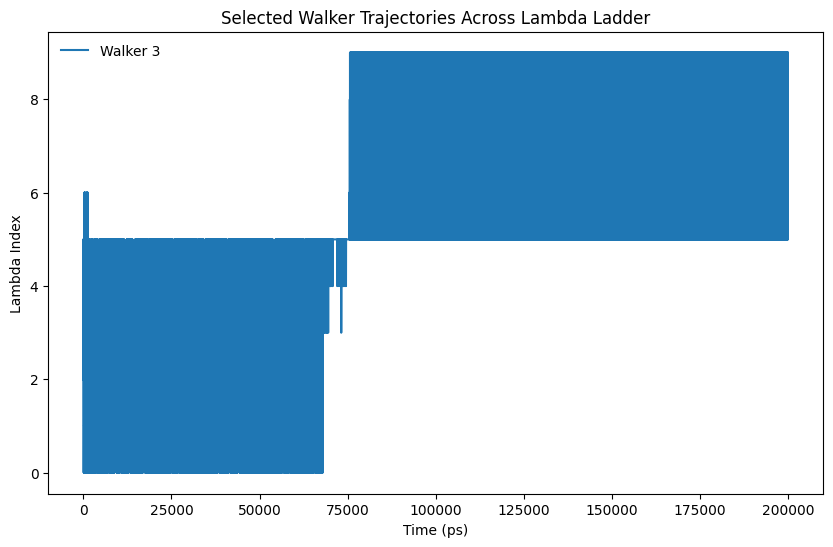

In [10]:
walkers_to_plot = [3]  # index in replica_temp (1 = λ001 walker)

plt.figure(figsize=(10,6))
for w in walkers_to_plot:
    plt.plot(time, rep[:, w], linewidth=1.5, label=f"Walker {w}")

plt.xlabel("Time (ps)")
plt.ylabel("Lambda Index")
plt.title("Selected Walker Trajectories Across Lambda Ladder")
plt.legend(ncol=3, frameon=False)
plt.show()


# Note:
**Walker 3 is particularly interesting:** it remains in the folded basin until ~60 ns, then briefly samples an intermediate-like conformation around ~75 ns before finally exchanging into the unfolded region. This trajectory segment may contain valuable structural information about the intermediate state, which has been difficult to capture in the 6ONI system.
____________________


### 🔁 Demuxed Trajectory Reconstruction  
Combine all replica trajectories using **trjcat with the demux file** to generate temperature-ordered (`T__trajout.xtc`) trajectories for further analysis.

### 🔁 REMD Exchange Logic

Walkers run MD → try to swap → continue at new temperatures:

🔴 T4: ④ →↔→ ③  
🟠 T3: ③ →↔→ ④  
🟢 T2: ② →↔→ ②  
🔵 T1: ① →✖️→ ①  

Successful swaps (↔) move walkers up/down the ladder, failed swaps (✖️) keep them in place.

**Result:** trajectories get *scrambled* 🔀 —  
demux + trjcat rebuild the *true* temperature-ordered paths 📈✨.


In [12]:
#Demuxed trajectories 
import subprocess

# Directories for your 10 replicas:
dirs = ["100", "102", "104", "106", "108", "110", "112", "114", "116", "118"]

# Construct the trjcat command with temperature-specific output names
cmd = (
    "gmx_mpi trjcat -cat "
    + "-f " + " ".join([f"{d}/traj_comp.xtc" for d in dirs])
    + " -demux replica_index.xvg "
    + "-o " + " ".join([f"{t}__trajout.xtc" for t in dirs])
)

print("Running:", cmd)
subprocess.run(cmd, shell=True)


Running: gmx_mpi trjcat -cat -f 100/traj_comp.xtc 102/traj_comp.xtc 104/traj_comp.xtc 106/traj_comp.xtc 108/traj_comp.xtc 110/traj_comp.xtc 112/traj_comp.xtc 114/traj_comp.xtc 116/traj_comp.xtc 118/traj_comp.xtc -demux replica_index.xvg -o 100__trajout.xtc 102__trajout.xtc 104__trajout.xtc 106__trajout.xtc 108__trajout.xtc 110__trajout.xtc 112__trajout.xtc 114__trajout.xtc 116__trajout.xtc 118__trajout.xtc


/bin/sh: ml: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `ml'
/bin/sh: find_port: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `find_port'
/bin/sh: which: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `which'
/bin/sh: create_passwd: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `create_passwd'
/bin/sh: random_number: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `random_number'
/bin/sh: module: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `module'
/bin/sh: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `setup_accre_software_stack'
/bin/sh: wait_until_port_used: line 1: syntax error: unexpected end of file
/bin/sh: error impor

Note that major changes are planned in future for trjcat, to improve usability and utility.Read 10 sets of 500000 points, dt = 0.4



CompletedProcess(args='gmx_mpi trjcat -cat -f 100/traj_comp.xtc 102/traj_comp.xtc 104/traj_comp.xtc 106/traj_comp.xtc 108/traj_comp.xtc 110/traj_comp.xtc 112/traj_comp.xtc 114/traj_comp.xtc 116/traj_comp.xtc 118/traj_comp.xtc -demux replica_index.xvg -o 100__trajout.xtc 102__trajout.xtc 104__trajout.xtc 106__trajout.xtc 108__trajout.xtc 110__trajout.xtc 112__trajout.xtc 114__trajout.xtc 116__trajout.xtc 118__trajout.xtc', returncode=0)

### 🔎 Extracting Native Contacts  
Pull the **[ pairs ]** section from the topology and save only the clean contact list (no headers or comments) into `file.cont` for further analysis.

Note: The contact-based analysis (from native contacts → WHAM → free-energy reconstruction) follows the workflow adapted from the SMOG2 tutorial: https://github.com/smog-server/SMOG2_tutorial

In [43]:
%%bash
# Extract the [ pairs ] section but skip the header/comment lines
awk '
  /^\s*\[\s*pairs\s*\]/{flag=1; next}
  /^\s*\[/{flag=0}
  flag && $1 !~ /^;/ {print}
' 6ONI-AA.top > file.cont

echo "✅ file.cont created (no header line)"
head -n 10 file.cont

bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

✅ file.cont created (no header line)
4	29	1	 1.029500664e-03 4.985484261e-07
4	33	1	 4.113287495e-03 7.958518275e-06
4	34	1	 2.396912093e-03 2.702453937e-06
4	35	1	 5.288025823e-03 1.315349675e-05
4	1694	1	 4.487415724e-02 9.472109240e-04
6	34	1	 1.782408016e-02 1.494405099e-04
6	35	1	 1.174695653e-02 6.490898393e-05
6	1664	1	 3.242750895e-02 4.946309222e-04
8	35	1	 2.491536810e-02 2.920039343e-04
8	1664	1	 2.556834893e-02 3.075101509e-04


### 🧮 Contact Map Computation  
Loop through each temperature folder and run the Python contact calculator to generate **contacts-AA-\<T\>.dat** files, logging all output to `out-contacts-AA.dat` for easy tracking.

In [44]:
%%bash
# List of temperatures (change if you have a different set)
temperatures="100 102 104 106 108 110 112 114 116 118"

# Remove old log
rm -f out-contacts-AA.dat

for T in $temperatures; do
  echo "🔍 Computing contacts for T=$T ..."
  
  (
    cd $T
    python3 ../../contacts-python/src/contacts_chunk.py \
        AA ../6ONI-AA-box.gro \
        traj_comp.xtc ../file.cont \
        contacts-AA-${T}.dat
  ) &>> out-contacts-AA.dat

done

echo "🎯 All contacts computed successfully."


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

🔍 Computing contacts for T=100 ...
🔍 Computing contacts for T=102 ...
🔍 Computing contacts for T=104 ...
🔍 Computing contacts for T=106 ...
🔍 Computing contacts for T=108 ...
🔍 Computing contacts for T=110 ...
🔍 Computing contacts for T=112 ...
🔍 Computing contacts for T=114 ...
🔍 Computing contacts for T=116 ...
🔍 Computing contacts for T=118 ...
🎯 All contacts computed successfully.


### 🧹 Energy Cleanup  
For each temperature folder, automatically detect the correct energy file, remove GROMACS headers, and extract clean **timestep** and **energy** arrays for downstream analysis.


In [45]:
%%bash

temps="100 102 104 106 108 110 112 114 116 118"

for T in $temps; do
  cd "$T" || continue

  # pick energy.xvg or potential.xvg
  if   [ -f energy.xvg    ]; then XVG=energy.xvg
  elif [ -f potential.xvg ]; then XVG=potential.xvg
  else
    echo "⚠️ No energy file found in $T"; cd ..; continue
  fi

  # Strip headers (@ or #) and split into two clean files
  grep -v '^[@#]' "$XVG" | awk '{print $1}' > "timestep-$T.dat"
  grep -v '^[@#]' "$XVG" | awk '{print $2}' > energy.dat

  echo "✅ $T cleaned: $(wc -l < energy.dat) energy points"
  cd ..
done

bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

✅ 100 cleaned: 200001 energy points
✅ 102 cleaned: 200001 energy points
✅ 104 cleaned: 200001 energy points
✅ 106 cleaned: 200001 energy points
✅ 108 cleaned: 200001 energy points
✅ 110 cleaned: 200001 energy points
✅ 112 cleaned: 200001 energy points
✅ 114 cleaned: 200001 energy points
✅ 116 cleaned: 200001 energy points
✅ 118 cleaned: 200001 energy points


### 🔗 Build Energy–Contact Files  
Combine each folder’s **energy.dat** and **contacts-AA-\<T\>.dat** into a unified `e-Q.dat` file, pairing potential energy with native contacts for every frame.


In [46]:
%%bash
echo "🔧 Creating e-Q.dat files (energy + contacts)..."

# Loop through each subdirectory (80, 90, ...)
for dir in */; do
  T="${dir%/}"  # remove trailing slash
  echo "📂 Processing $T ..."

  # Check if input files exist before pasting
  if [[ -f "$T/energy.dat" && -f "$T/contacts-AA-$T.dat" ]]; then
    paste -d " " "$T/energy.dat" "$T/contacts-AA-$T.dat" > "$T/e-Q.dat"
    echo "✅ $T/e-Q.dat created ($(wc -l < "$T/e-Q.dat") frames)"
  else
    echo "❌ Skipping $T — missing energy.dat or contacts-AA-$T.dat"
  fi

  sleep 0.2
done

echo "🎯 All available e-Q.dat files have been generated."


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

🔧 Creating e-Q.dat files (energy + contacts)...
📂 Processing 100 ...
✅ 100/e-Q.dat created (200001 frames)
📂 Processing 102 ...
✅ 102/e-Q.dat created (200001 frames)
📂 Processing 104 ...
✅ 104/e-Q.dat created (200001 frames)
📂 Processing 106 ...
✅ 106/e-Q.dat created (200001 frames)
📂 Processing 108 ...
✅ 108/e-Q.dat created (200001 frames)
📂 Processing 110 ...
✅ 110/e-Q.dat created (200001 frames)
📂 Processing 112 ...
✅ 112/e-Q.dat created (200001 frames)
📂 Processing 114 ...
✅ 114/e-Q.dat created (200001 frames)
📂 Processing 116 ...
✅ 116/e-Q.dat created (200001 frames)
📂 Processing 118 ...
✅ 118/e-Q.dat created (200001 frames)
🎯 All available e-Q.dat files have been generated.


### 🔎 Pre-WHAM Range Inspection  
Use the output from this scan to guide WHAM settings — the observed **energy** and **Q** ranges determine the appropriate `start`, `step`, and `numBins` values in the next configuration step.


In [47]:
import numpy as np
import glob
import os

files = sorted(glob.glob("*/e-Q.dat"), key=lambda x: int(x.split("/")[-2]))

if not files:
    raise RuntimeError("No e-Q.dat files found!")

print(f"{'Temp(K)':>7}  {'E_min':>12}  {'E_max':>12}  {'Q_min':>10}  {'Q_max':>10}")
print("-"*60)

for f in files:
    T = os.path.basename(os.path.dirname(f))
    try:
        data = np.loadtxt(f, comments="#")
    except Exception as e:
        print(f"⚠️ {T}: Failed to read ({e})")
        continue

    if data.ndim != 2 or data.shape[1] < 2:
        print(f"⚠️ {T}: Malformed data, skipping")
        continue

    E = data[:, 0]  # energy
    Q = data[:, 1]  # contacts

    print(f"{T:>7}  {E.min():12.3f}  {E.max():12.3f}  {Q.min():10.3f}  {Q.max():10.3f}")


Temp(K)         E_min         E_max       Q_min       Q_max
------------------------------------------------------------
    100     -1438.069      2096.163    1935.000    2694.000
    102     -1438.070      2211.604    1876.000    2694.000
    104     -1438.069      2296.444    1756.000    2694.000
    106     -1438.070      2447.311    1624.000    2694.000
    108     -1438.070      2576.236    1280.000    2694.000
    110     -1438.070      3386.154      84.000    2694.000
    112     -1438.070      3442.129      76.000    2694.000
    114     -1438.070      3495.184      71.000    2694.000
    116     -1438.069      3560.315      67.000    2694.000
    118     -1438.070      3640.755      67.000    2694.000


### 🔎 Parameter Check for WHAM  
From the scan above, **E_min ≈ –1438 kJ/mol**, so setting:

- **`start -1500`** → safely below the lowest observed energy  
- **`numBins 2700`** → wide enough to cover the full energy span up to ~3600  

This ensures the WHAM histogram includes all sampled states without clipping.
_________

### 📝 WHAM Configuration Setup  
Create a clean `config_wham.txt` file for 2D WHAM analysis, defining histogram bins, input trajectory files, and all thermodynamic outputs (DOS, Cv, free energy, coordinate scans).


In [10]:
%%bash
mkdir -p ../Wham/6ONI
cd ../Wham/6ONI

cat > config_wham.txt <<'EOF'
kB 0.008314 # Boltzmann constant
tolerance 0.00001 # convergence criterion
overwriting # allow overwrite of previous outputs
threads 6   # use 6 cores

##### define internal histograming #####
numDimensions 2 # columns: Potential_energy and Q

# Energy histogram bins (excluding outliers from 320/350/360/370 K)
numBins 600
start -1500       # slightly below min energy (-1438.070)
step 20           # bin width chosen to cover ~11000 kJ/mol max safely

# Q histogram bins
numBins 2700
start 0
step 1

##### trajectory files (2 columns: Potential_energy and Q)
numFiles 10
name /work/6ONI/100/e-Q.dat temp 100
name /work/6ONI/102/e-Q.dat temp 102
name /work/6ONI/104/e-Q.dat temp 104
name /work/6ONI/106/e-Q.dat temp 106
name /work/6ONI/108/e-Q.dat temp 108
name /work/6ONI/110/e-Q.dat temp 110
name /work/6ONI/112/e-Q.dat temp 112
name /work/6ONI/114/e-Q.dat temp 114
name /work/6ONI/116/e-Q.dat temp 116
name /work/6ONI/118/e-Q.dat temp 118

run_wham
dosFile dos.dat

run_cv
startT 100
deltaT 0.2
ntemps 100
run_cv_out cv.dat

run_free
startTF 100
deltaTF 0.2
ntempsF 100
run_free_out free/

run_coord
startTC 100
deltaTC 0.2
ntempsC 100
run_coord_out coord.dat
EOF

echo "✅ Cleaned config_wham.txt created in $(pwd)"


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

✅ Cleaned config_wham.txt created in /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Exchange/Wham/6ONI


### 🚀 Running WHAM  
Execute **WHAM.jar** inside the Apptainer container, using the edited paths in `config_wham.txt` (mapped to `/work`) to perform the full multi-temperature WHAM analysis.


### 🚀 Running WHAM  
Execute **WHAM.jar** inside the Apptainer container, using the edited paths in `config_wham.txt` (mapped to `/work`) to perform the full multi-temperature WHAM analysis.


In [11]:
%%bash
cd ../Wham/6ONI
#Here we ask the apptainer to execute at .. which we call the /work directory hence we had to edit file names above in the WHAM config file

echo "🚀 Running WHAM.jar with config_wham.txt ..."
apptainer exec --bind /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Exchange/:/work \
  ~/smog2.sif java -Xmx1g -jar /opt/smog2/src/tools/WHAM.jar \
  --config /work/Wham/6ONI/config_wham.txt


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

🚀 Running WHAM.jar with config_wham.txt ...
Parsing configuration file: /work/Wham/6ONI/config_wham.txt

Listing files and temperatures
/work/6ONI/100/e-Q.dat 100.0
/work/6ONI/102/e-Q.dat 102.0
/work/6ONI/104/e-Q.dat 104.0
/work/6ONI/106/e-Q.dat 106.0
/work/6ONI/108/e-Q.dat 108.0
/work/6ONI/110/e-Q.dat 110.0
/work/6ONI/112/e-Q.dat 112.0
/work/6ONI/114/e-Q.dat 114.0
/work/6ONI/116/e-Q.dat 116.0
/work/6ONI/118/e-Q.dat 118.0

Scaling temperatures * kB
Running high precision WHAM calculation.
Reading in histograms.
/work/6ONI/100/e-Q.dat 200001 lines.
/work/6ONI/102/e-Q.dat 200001 lines.
/work/6ONI/104/e-Q.dat 200001 lines.
/work/6ONI/106/e-Q.dat 200001 lines.
/work/6ONI/108/e-Q.dat 200001 lines.
/work/6ONI/110/e-Q.dat 200001 lines.
/work/6ONI/112/e-Q.dat 200001 lines.
/work/6ONI/114/e-Q.dat 200001 lines.
/work/6ONI/116/e-Q.dat 200001 lines.
/work/6ONI/118/e-Q.dat 200001 lines.

Sum total configurations.
/work/6ONI/100/e-Q.dat 200001
/work/6ONI/102/e-Q.dat 200001
/work/6ONI/104/e-Q.dat 200

### 🌡️ Specific Heat Curve  
Plot the **Cv vs. Temperature** profile from WHAM to identify thermal transitions 

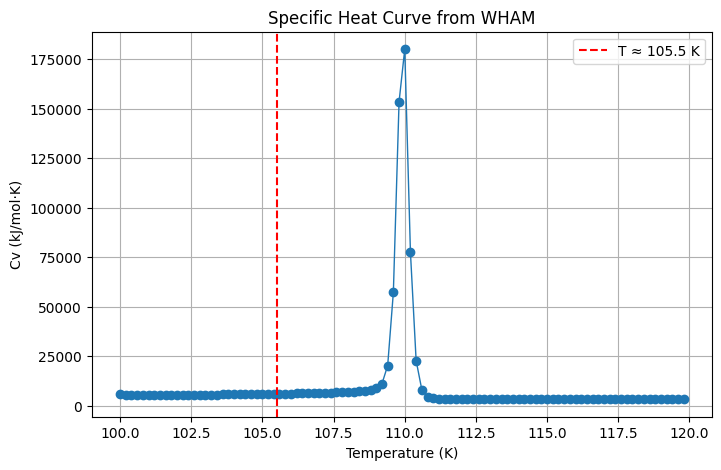

In [12]:
import numpy as np
import matplotlib.pyplot as plt

cv = np.loadtxt("../Wham/6ONI/cv.dat")
T, Cv = cv[:,0], cv[:,1]

plt.figure(figsize=(8,5))
plt.plot(T, Cv, marker="o", lw=1)
plt.axvline(105.5, color="r", ls="--", label="T ≈ 105.5 K")
plt.xlabel("Temperature (K)")
plt.ylabel("Cv (kJ/mol·K)")
plt.title("Specific Heat Curve from WHAM")
plt.legend()
plt.grid()
plt.show()


### 🔍 Interpretation of the Specific Heat Curve (6ONI)

The WHAM-derived specific heat curve for **6ONI** shows a single dominant peak near  
**~109.5–110 K**, indicating a **cooperative unfolding transition** without a clearly resolved intermediate state. Unlike 6ONJ and 3PRG—where helix 12 is displaced from the pocket and the \( C_V(T) \) profiles display two well-separated peaks corresponding to **N → I** and **I → U** transitions—6ONI exhibits a smoother, more continuous rise in heat capacity.

The system appears to transition gradually with an increase in slope from the native ensemble into the unfolded ensemble with no strong evidence of well defined intermediate like we observe in 6ONJ and 3PRG.

This behavior implies that, in the 6ONI starting conformation, the partially folded or “intermediate-like” structures may be **weakly populated** and **not thermodynamically isolated**. The likely reason is the **anchored position of helix 12 within the pocket**, which restricts the structural rearrangements needed to form a stable intermediate state. As a result, the unfolding process appears more two-state-like, lacking the clearly separated **N → I → U** progression seen in agonist-activated structures.

Overall, the single sharp peak indicates that **6ONI unfolds into unfolded states**, with any intermediate conformations being transient and not strong enough to generate a separate signature in the heat-capacity profile.


Found 100 free-energy profiles.


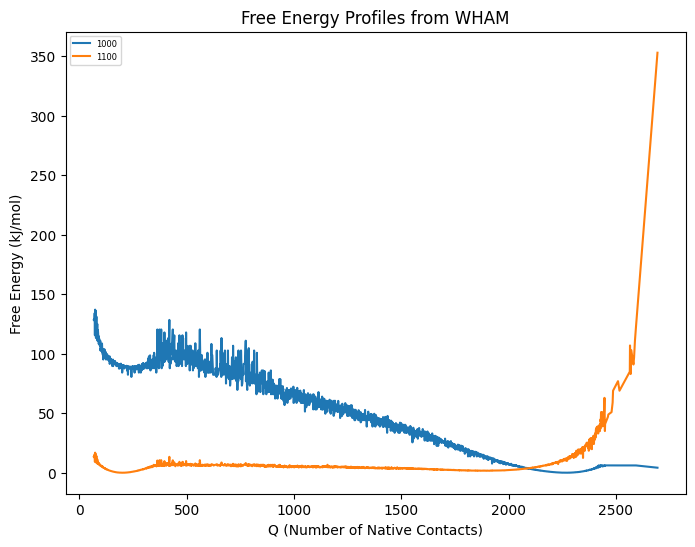

In [13]:
#free energies have not shown a smooth profile, the sampling around 122 may be improved
import numpy as np
import glob
import matplotlib.pyplot as plt

free_files = sorted(glob.glob("../Wham/6ONI/free/*"))
print(f"Found {len(free_files)} free-energy profiles.")

plt.figure(figsize=(8,6))
for f in free_files[::50]:  # plot every 50th to avoid clutter
    data = np.loadtxt(f)
    Q, F = data[:,0], data[:,1]
    plt.plot(Q, F, label=f.split('/')[-1])

plt.xlabel("Q (Number of Native Contacts)")
plt.ylabel("Free Energy (kJ/mol)")
plt.title("Free Energy Profiles from WHAM")
plt.legend(fontsize=6)
plt.show()

### 🔍 Understanding the WHAM Free-Energy Curves

The WHAM setup reconstructs free-energy surfaces over a continuous temperature range from 100 K upward in 0.2 K increments, generating 100 individual free-energy profiles, and the two curves shown arise simply because the plotting script subsampled this directory (`free_files[::50]`) and therefore selected one profile near 100 K and another near 110 K; this is not due to using two CVs, since WHAM was run with a single reaction coordinate (Q) together with potential energy as a second dimension for histogramming. 

### 📈 What the Q-Axis Represents

In this SMOG/WHAM representation, the Q-axis corresponds to internal histogram bin indices rather than the absolute number of native contacts, which is why the values fall in the 100000–110000 range, and lower Q-bin values represent more native-like structures while higher values reflect progressively unfolded states.

### 🧬 Interpreting the Two Curves

The free-energy curve (blue) 100 K displays a minima at 2300 and a lighter one around 1700 and the unfolded basin near 0, consistent with the system remaining in the native basin unlike 3PRG and 6ONJ there is no minima near 1500 suggesting that the intermediate is not populated or observable clearly, whereas the curve for 110 K (orange) shows the unfolded basin flattened ( Q near 0) and folded regions (above 1000 contacts) with increasing free energy, suggesting the system rolls into unfolded states.
*********************************************

### 🌡️ Free Energy Landscape at **106 K** 

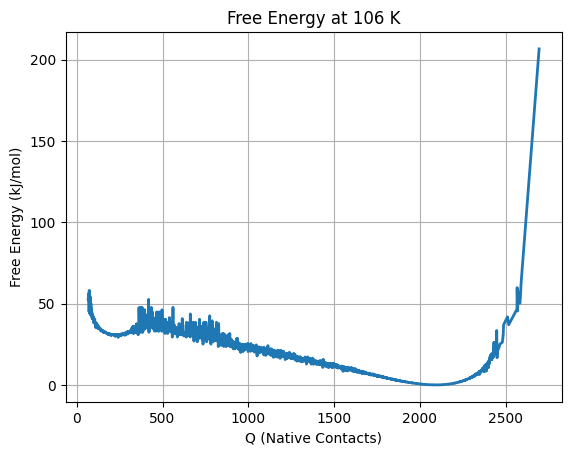

In [14]:
import numpy as np, glob, matplotlib.pyplot as plt

# Find the file for 106 K
files = glob.glob("../Wham/6ONI/free/*106*")
if not files: raise FileNotFoundError("No 106 K free-energy file found.")
data = np.loadtxt(files[0])

plt.plot(data[:,0], data[:,1], lw=2)
plt.xlabel("Q (Native Contacts)")
plt.ylabel("Free Energy (kJ/mol)")
plt.title("Free Energy at 106 K")
plt.grid()
plt.show()


### 🔍 Interpretation of the Free-Energy Profile at 106 K

#### **Intermediate state dosent have a basin like 3PRG and 6ONJ**
For 3PRG and 6ONJ at **108 K** and **106 K** we observe a basin but for 6ONI this basin dosent appear. The free energy follows a gradual increase towards the unfolded regime. Instead the Native basin appears to have blended in with the intermediate state basin. 

#### **Destabilization of the Native State**
The native basin at high Q (Q ≈ 2300–2600) is still present but lies as a mixture of ensembles tending more todards the intermedaite states seen with ~ 1600 contacts in 3PRG and 6ONJ. Also the basin shifts left towards the intermedate ( 1600) suggesting that the intermedaite could be partially sampled at this state. 

#### **Overall Insight**
The free-energy profile at 106 K demonstrates that this temperature the native comformation is still dominant with traces of intermedaite whcih required further clustering and ensemble analysis.
_____________________

### 📥 Reading All `e-Q.dat` Files into DataFrames

First we define a helper (`read_eQ`) to load each `e-Q.dat` file into a clean Pandas DataFrame with **Potential** and **Q** columns.  
Then we loop through all temperature folders (**100 → 118 K**) and collect the data into `all_frames` for combined analysis. 🚀

In [15]:
import pandas as pd, os

def read_eQ(path):
    """Read energy + Q from e-Q.dat (two columns: energy, contacts)."""
    fname = os.path.join(path, "e-Q.dat")
    if not os.path.exists(fname):
        raise FileNotFoundError(f"{fname} not found")
    df = pd.read_csv(fname, sep=r'\s+', comment='#', header=None, engine='python')
    df = df.rename(columns={0:"Potential", 1:"Q"})
    return df.dropna().reset_index(drop=True)


In [16]:
all_frames = []

for folder in range(100, 119, 2):   # 100, 102, 104, ..., 118
    folder = str(folder)
    fname = os.path.join(folder, "e-Q.dat")

    if os.path.exists(fname):
        print("Reading:", fname)
        df = read_eQ(folder)
        all_frames.append(df)
    else:
        print("Skipping (not found):", fname)


Reading: 100/e-Q.dat
Reading: 102/e-Q.dat
Reading: 104/e-Q.dat
Reading: 106/e-Q.dat
Reading: 108/e-Q.dat
Reading: 110/e-Q.dat
Reading: 112/e-Q.dat
Reading: 114/e-Q.dat
Reading: 116/e-Q.dat
Reading: 118/e-Q.dat


### 📊 Combined Q-Distribution Across All Replicas  
After loading all `e-Q.dat` files, we merge them into one DataFrame and plot the overall **distribution of native contacts (Q)**.  
This gives a quick global view of how the system samples **unfolded → intermediate → folded** states across the full temperature ladder. 🔥❄️


In [17]:
frames = pd.concat(all_frames, ignore_index=True)

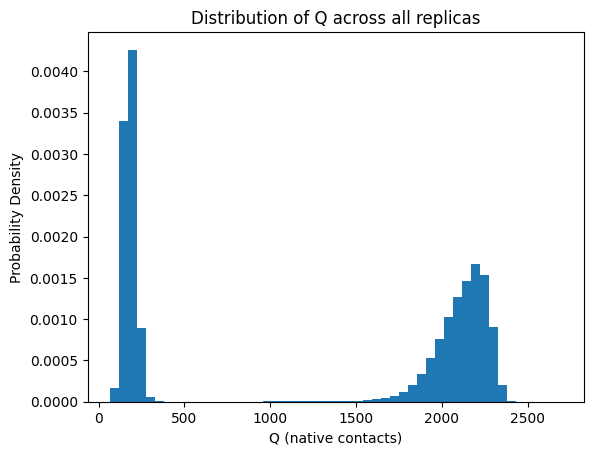

In [18]:
import matplotlib.pyplot as plt
plt.hist(frames["Q"], bins=50, density=True)
plt.xlabel("Q (native contacts)")
plt.ylabel("Probability Density")
plt.title("Distribution of Q across all replicas")
plt.show()


### 🔍 Results from the Global Q-Distribution Across All Temperatures

This combined histogram captures **native, intermediate, and unfolded conformations sampled across all replicas**.  
The **left peak (~0–300)** represents unfolded states.  
The **broad middle region (~1200–1700)**—barely visible in the individual temperature-specific plots—appears here as a small but clear population, indicating that sampling of this intermediate is rare yet accessible.  
The **right peak (~1900–2400)** corresponds to folded conformations.

Taken together, these three clusters demonstrate that the replica-exchange ladder successfully explores the complete folding landscape.
___________________


### 🔄 NEXT CELL: Reweighting Replica-Exchange Data to a Target Temperature

This cell performs **Boltzmann reweighting** of all replicas (100–118 K) to estimate the  
**native, intermediate, and unfolded state populations** at a chosen temperature (e.g., **110 K**).

**What this cell does:**
- 📥 **Loads all e–Q.dat files** (Potential, Q) from each replica.
- 📊 **Defines structural states** using Q ranges (unfolded / intermediate / native).
- 🔢 **Computes statistical weights** for each frame so they correspond to a **target temperature**.
- 🧮 **Reports reweighted populations** of all states at that temperature.
- 🌡️ **Prints raw populations per replica** to visualize how sampling shifts with temperature.
- 🧭 **Sweeps over all target temperatures**, giving state populations at every T.

This produces a **thermodynamic map** of your folding landscape, reconstructed from replica-exchange sampling.


In [29]:
import numpy as np
import pandas as pd
import os

# === USER SETTINGS (EDIT FOR NEW RUNS) ===
dirs = ["100","102","104","106","108","110","112","114","116","118"]  # temperature directories
target_T = 110.0          # target temperature for reweighting (K)
kB = 0.008314462618       # kJ/mol/K

# === STATE DEFINITIONS (Q ranges) ===
# You can use None for open-ended ranges
Q_RANGES = {
    "unfolded":    (None,  500),    # Q <= 500
    "intermediate":( 500, 1800),   # 500 < Q <= 1950
    "native":      (1800, None)    # Q > 1950
}

# === Helper: read e-Q.dat (energy + Q) ===
def read_eQ(path):
    fname = os.path.join(path, "e-Q.dat")
    if not os.path.exists(fname):
        raise FileNotFoundError(f"{fname} not found")
    df = pd.read_csv(fname, sep=r'\s+', comment='#', header=None, engine='python')
    df = df.rename(columns={0:"Potential", 1:"Q"})
    return df.dropna().reset_index(drop=True)

# === Load all replicas ===
blocks = []
for d in dirs:
    df = read_eQ(d)
    df["T"] = float(d)
    blocks.append(df)
frames = pd.concat(blocks, ignore_index=True)

# === Compute weights for reweighting to target_T ===
beta_star = 1.0 / (kB * target_T)
beta_k    = 1.0 / (kB * frames["T"].values)
E         = frames["Potential"].values
logw = -(beta_star - beta_k) * E
logw -= np.max(logw)
w = np.exp(logw)
w /= np.sum(w)

Q = frames["Q"].values

# === Classify frames based on Q_RANGES ===
def classify(Q, ranges):
    states = {}
    for name, (low, high) in ranges.items():
        if low is None:
            mask = Q <= high
        elif high is None:
            mask = Q > low
        else:
            mask = (Q > low) & (Q <= high)
        states[name] = mask
    return states

states = classify(Q, Q_RANGES)

# === Print reweighted populations ===
def sci(x): return f"{x:.4e}"

print(f"\n=== Reweighted Populations at {target_T:.1f} K ===")
for name, mask in states.items():
    P = np.sum(w * mask)
    print(f"P({name}) = {sci(P)}")

if np.sum(w * states["unfolded"]) > 0:
    ratio = np.sum(w * states["native"]) / np.sum(w * states["unfolded"])
    print(f"Native/Unfolded ratio = {ratio:.3e}")

# === Per-replica raw populations (no reweighting) ===
print("\n=== Per-Replica Populations (Raw) ===")
temps = sorted(frames["T"].unique())
for T in temps:
    dfT = frames[frames["T"]==T]
    qT = dfT["Q"].values
    sT = classify(qT, Q_RANGES)
    fractions = {name: sT[name].mean() for name in Q_RANGES}
    frac_str = "  ".join(f"{n}={fractions[n]:.3f}" for n in Q_RANGES)
    print(f"{int(T):3d}K  {frac_str}")

# === Sweep reweighting over all target temperatures ===
print("\n=== Reweighted Populations Across Target Temperatures ===")
for Tstar in temps:
    beta_star = 1.0 / (kB * Tstar)
    logw = -(beta_star - beta_k) * E
    logw -= np.max(logw)
    wT = np.exp(logw)
    wT /= np.sum(wT)
    fracs = {name: np.sum(wT * states[name]) for name in Q_RANGES}
    frac_str = "  ".join(f"{n}={fracs[n]:.3f}" for n in Q_RANGES)
    print(f"T*={int(Tstar):3d}K  {frac_str}")



=== Reweighted Populations at 110.0 K ===
P(unfolded) = 2.1692e-95
P(intermediate) = 1.9886e-38
P(native) = 1.0000e+00
Native/Unfolded ratio = 4.610e+94

=== Per-Replica Populations (Raw) ===
100K  unfolded=0.000  intermediate=0.000  native=1.000
102K  unfolded=0.000  intermediate=0.000  native=1.000
104K  unfolded=0.000  intermediate=0.000  native=1.000
106K  unfolded=0.000  intermediate=0.001  native=0.999
108K  unfolded=0.000  intermediate=0.037  native=0.963
110K  unfolded=0.622  intermediate=0.145  native=0.233
112K  unfolded=0.992  intermediate=0.006  native=0.002
114K  unfolded=0.999  intermediate=0.001  native=0.000
116K  unfolded=0.999  intermediate=0.001  native=0.000
118K  unfolded=0.999  intermediate=0.001  native=0.000

=== Reweighted Populations Across Target Temperatures ===
T*=100K  unfolded=0.000  intermediate=0.000  native=1.000
T*=102K  unfolded=0.000  intermediate=0.000  native=1.000
T*=104K  unfolded=0.000  intermediate=0.000  native=1.000
T*=106K  unfolded=0.000 

### 📊 Temperature-Dependent State Populations (Raw Fractions)

This cell computes **native**, **intermediate**, and **unfolded** populations for each replica temperature using the `Q` order parameter:

- **Unfolded** → `Q ≤ 500`  
- **Intermediate** → `500 < Q ≤ 1800`  
- **Native** → `Q > 1800`

For every temperature folder (`100–118 K`), the script:
1. 📥 **Loads the corresponding `e-Q.dat`** file  
2. 📊 **Computes raw state fractions** (no reweighting)  
3. 📈 **Plots how each population evolves with temperature**  
4. ⚡ **Calculates ΔG values** for the transitions  
   - ΔG(N→I)  
   - ΔG(I→U)

This gives a clear picture of **which states dominate at each temperature** and how stability shifts across the λ-ladder before performing any WHAM or reweighting.



=== Per-Replica Populations (Raw Fractions) ===
100K  native=1.000  interm=0.000  unfold=0.000
102K  native=1.000  interm=0.000  unfold=0.000
104K  native=1.000  interm=0.000  unfold=0.000
106K  native=0.999  interm=0.001  unfold=0.000
108K  native=0.963  interm=0.037  unfold=0.000
110K  native=0.233  interm=0.145  unfold=0.622
112K  native=0.002  interm=0.006  unfold=0.992
114K  native=0.000  interm=0.001  unfold=0.999
116K  native=0.000  interm=0.001  unfold=0.999
118K  native=0.000  interm=0.001  unfold=0.999


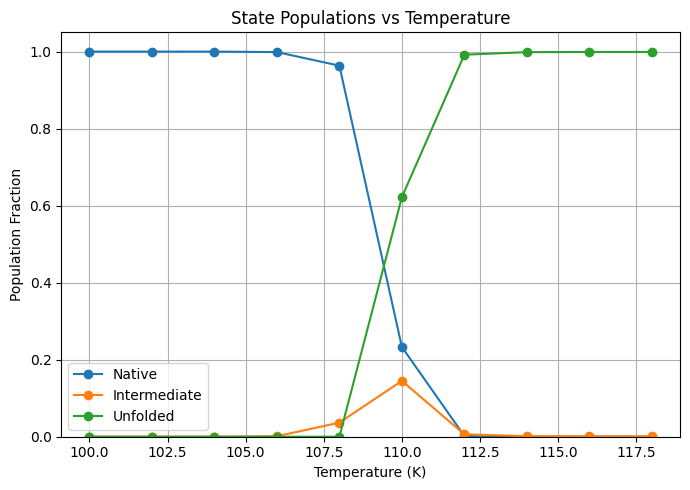


=== Free Energy Differences (kJ/mol) ===
104K  ΔG(N→I) = 9.60 kJ/mol
106K  ΔG(N→I) = 5.86 kJ/mol
108K  ΔG(N→I) = 2.94 kJ/mol
110K  ΔG(N→I) = 0.43 kJ/mol
110K  ΔG(I→U) = -1.33 kJ/mol
112K  ΔG(N→I) = -1.12 kJ/mol
112K  ΔG(I→U) = -4.73 kJ/mol
114K  ΔG(N→I) = -2.63 kJ/mol
114K  ΔG(I→U) = -6.25 kJ/mol
116K  ΔG(N→I) = -2.66 kJ/mol
116K  ΔG(I→U) = -6.80 kJ/mol
118K  ΔG(N→I) = -2.87 kJ/mol
118K  ΔG(I→U) = -6.95 kJ/mol


In [30]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

# === USER SETTINGS ===
dirs = ["100","102","104","106","108","110","112","114","116","118"]
kB = 0.008314462618  # kJ/mol/K

# === Q STATE CUTS (edit here if needed) ===
Q_unfolded_cutoff = 500    # unfolded: Q <= 500
Q_native_cutoff   = 1800  # native:   Q > 1950

def read_eQ(path):
    fname = os.path.join(path, "e-Q.dat")
    if not os.path.exists(fname):
        raise FileNotFoundError(f"{fname} not found")
    df = pd.read_csv(fname, sep=r'\s+', comment='#', header=None, engine='python')
    df = df.rename(columns={0:"Potential", 1:"Q"})
    return df.dropna().reset_index(drop=True)

# === Load data ===
blocks = []
for d in dirs:
    df = read_eQ(d)
    df["T"] = float(d)
    blocks.append(df)
frames = pd.concat(blocks, ignore_index=True)

temps = sorted(frames["T"].unique())
pop_native, pop_intermediate, pop_unfolded = [], [], []

print("\n=== Per-Replica Populations (Raw Fractions) ===")
for T in temps:
    dfT = frames[frames["T"]==T]
    qT = dfT["Q"].values

    is_unfolded    = qT <= Q_unfolded_cutoff
    is_native      = qT >  Q_native_cutoff
    is_intermediate = ~(is_unfolded | is_native)

    p_unf = is_unfolded.mean()
    p_nat = is_native.mean()
    p_int = is_intermediate.mean()

    pop_unfolded.append(p_unf)
    pop_native.append(p_nat)
    pop_intermediate.append(p_int)

    print(f"{int(T):3d}K  native={p_nat:.3f}  interm={p_int:.3f}  unfold={p_unf:.3f}")

# === Plot populations vs temperature ===
plt.figure(figsize=(7,5))
plt.plot(temps, pop_native, 'o-', label="Native")
plt.plot(temps, pop_intermediate, 'o-', label="Intermediate")
plt.plot(temps, pop_unfolded, 'o-', label="Unfolded")
plt.xlabel("Temperature (K)")
plt.ylabel("Population Fraction")
plt.title("State Populations vs Temperature")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# === Compute ΔG values for N⇆I and I⇆U ===
R = kB
print("\n=== Free Energy Differences (kJ/mol) ===")
for T, pn, pi, pu in zip(temps, pop_native, pop_intermediate, pop_unfolded):
    if pn > 0 and pi > 0:
        dG_NI = -R * T * np.log(pi/pn)
        print(f"{int(T):3d}K  ΔG(N→I) = {dG_NI:.2f} kJ/mol")
    if pi > 0 and pu > 0:
        dG_IU = -R * T * np.log(pu/pi)
        print(f"{int(T):3d}K  ΔG(I→U) = {dG_IU:.2f} kJ/mol")


## 🔍 State Populations Across Temperature
The population analysis reveals a not so clear N → I → U progression in the SMOG folding model. At low temperatures (100–106 K), the protein is almost exclusively in the native basin (Q > 1800). As the temperature increases to 110 K, the intermediate state (Q ≈ 1400–1800) is slightly populated, indicating transient sampling. At temperatures above 110 K, the population shifts entirely into the unfolded regime (Q < 500), reflecting the onset of global unfolding. The derived free-energy differences ΔG(N→I) follow the same pattern, crossing zero near the midpoint of the N → I transition (~108–110 K), confirming that the intermediate becomes thermodynamically favored in this temperature window.

**Note that the intermediate is highly populated in 6ONJ in comparison to 3PRG where native, intermediate and unfolded co-exsist.**

## 📉 Free-Energy Differences (ΔG)
The ΔG values computed from the state populations mirror the observed population shifts. Positive ΔG(N→I) at low temperature indicates strong native stability, while negative values above ~110 K indicate that the intermediate or unfolded states are more stable. These ΔG values quantify the relative stabilities of the three ensembles within the model and track the progressive destabilization of the native structure as temperature rises.

## ⚠️ Limitations of This Analysis 
This method has several important caveats. First, the SMOG/Go model produces model-level thermodynamics because it lacks explicit solvent and realistic energetic contributions, so ΔG values should not be interpreted as physical free energies. Second, the population and ΔG estimates depend on the choice of Q cutoffs that define native, intermediate, and unfolded states; while the qualitative N → I → U pattern is robust, the numerical values can shift slightly with different thresholds. Third, the analysis assumes equilibrium populations; insufficient sampling, especially in the unfolded region, can bias ΔG(I→U). Finally, Q is a one-dimensional reaction coordinate and may not fully resolve all structural sub-states, particularly within partially unfolded or highly heterogeneous regions.

## ✅ Overall
Taken together, the state populations and ΔG values provide a coherent and internally consistent picture of a three-state folding landscape. The native and unfolded ensembles are well separated; the intermediate appears to be sampled alightly at 110K;

-------------------------------
-----------------------------


### 📦 Extracting Structural Frames from Demuxed Trajectories  
All scripts below convert the **demuxed replica trajectories** (`*_trajout.xtc`) into **PDB frame sets**, allowing structural inspection and state visualization.  

In [88]:
%%bash
echo 1 1 | gmx_mpi trjconv -f 104__trajout.xtc -s 104/t-6ONI.tpr -skip 50 -center -pbc mol -o 104__trajout.pdb

bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for centering
Selected 1: 'Protein'
Select group for output
Selected 1: 'Protein'


In [76]:
%%bash
echo 1 1 | gmx_mpi trjconv -f 106/traj_comp.xtc -s 106/t-6ONI.tpr -skip 50 -center -pbc mol -o 106/106_traj_comp.pdb

bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for centering
Selected 1: 'Protein'
Select group for output
Selected 1: 'Protein'


check 106 (frame 462) and 102 trajectories which have intermediate state. Overall its much more sparse sampling than imn 6ONJ and helix 12 is still inside but the contacts are lot an its defimnitely the sparese intermedaite. 

104 trajectory unfolds, that is it moves from folded to unfolded in the sims (check walker plot 3 ) this system explores the common link between the 6ONJ and 6ONI systems ! Here is the missing link and the puzzle ! 